# 1.0 Where does the financial pressure sit?

**Board question:** how many trusts are in deficit, in which sectors, and is it getting worse?

The analysis is done in SQL. Every query lives in
[`sql/analysis/01_financial_pressure.sql`](../../sql/analysis/01_financial_pressure.sql) and runs against the MySQL warehouse
(`nhs_gold` views and the `nhs_silver.fct_tac` fact table). Each section below shows the query exactly as
it is in that file, then its result. Python only runs the query and, in one place, draws a chart from the
result.

| Query | SQL technique |
| --- | --- |
| `deficit_share_by_sector` | Conditional aggregation, `WITH ROLLUP`, `GROUPING()` |
| `sector_result_trend` | CTE + `LAG()` over a named `WINDOW` |
| `margin_distribution_latest_year` | Median without `MEDIAN()`: `ROW_NUMBER()` + `COUNT() OVER` |
| `surplus_deficit_transitions` | `LAG()` to pair years, then a pivot of transitions |
| `largest_deficits_with_impairments` | EAV pivot from the fact table, top N per group |

**Data:** NHS England Trust Accounts Consolidation (TAC), annual and actuals only. Money is held in £000s;
columns ending `_m` are £m. Operating surplus is the SoCI line `SCI0140A` as each trust reported it, which
includes impairments (non-cash write-downs). No query is pinned to a year: each one reads the year range
from the data.

To run it: load the warehouse, `export DB_PASSWORD=...`, then run all cells.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Make analysis/nhs_analysis.py importable from the repo root or from this folder
here = Path.cwd()
sys.path.insert(0, str(here.parent if here.name == "notebooks" else here / "analysis"))
import nhs_analysis as nhs

nhs.set_style()
pd.options.display.float_format = "{:,.1f}".format
pd.options.display.max_columns = 20

## 1.1 Share of trusts in deficit, by sector

`WITH ROLLUP` adds a national subtotal for each year in the same pass, and `GROUPING()` labels those rows
*All sectors* instead of leaving a `NULL`. `AVG(condition)` gives the share directly, because MySQL treats a
true comparison as 1.

In [2]:
deficit = nhs.sql("01_financial_pressure", "deficit_share_by_sector")
deficit

`sql/analysis/01_financial_pressure.sql` → **deficit_share_by_sector**

```sql
-- How many trusts in each sector reported an operating deficit, by year, with a
-- national total per year.
-- Technique: conditional aggregation, GROUP BY ... WITH ROLLUP for subtotals, and
-- GROUPING() to label the subtotal rows instead of leaving NULLs.
SELECT
    financial_year,
    IF(GROUPING(sector) = 1, 'All sectors', sector)            AS sector,
    COUNT(*)                                                    AS trusts,
    SUM(CASE WHEN operating_surplus_000s < 0 THEN 1 ELSE 0 END) AS trusts_in_deficit,
    ROUND(100 * AVG(operating_surplus_000s < 0), 1)             AS pct_in_deficit
FROM v_kpis
GROUP BY financial_year, sector WITH ROLLUP
HAVING GROUPING(financial_year) = 0
ORDER BY financial_year, GROUPING(sector), sector;
```

,financial_year,sector,trusts,trusts_in_deficit,pct_in_deficit
0,2021/22,Acute,123,22,17.9
1,2021/22,Ambulance,10,2,20.0
2,2021/22,Community,18,3,16.7
3,2021/22,Mental Health,48,10,20.8
4,2021/22,Specialist,16,1,6.3
5,2021/22,All sectors,215,38,17.7
6,2022/23,Acute,121,58,47.9
7,2022/23,Ambulance,10,3,30.0
8,2022/23,Community,18,7,38.9
9,2022/23,Mental Health,47,17,36.2


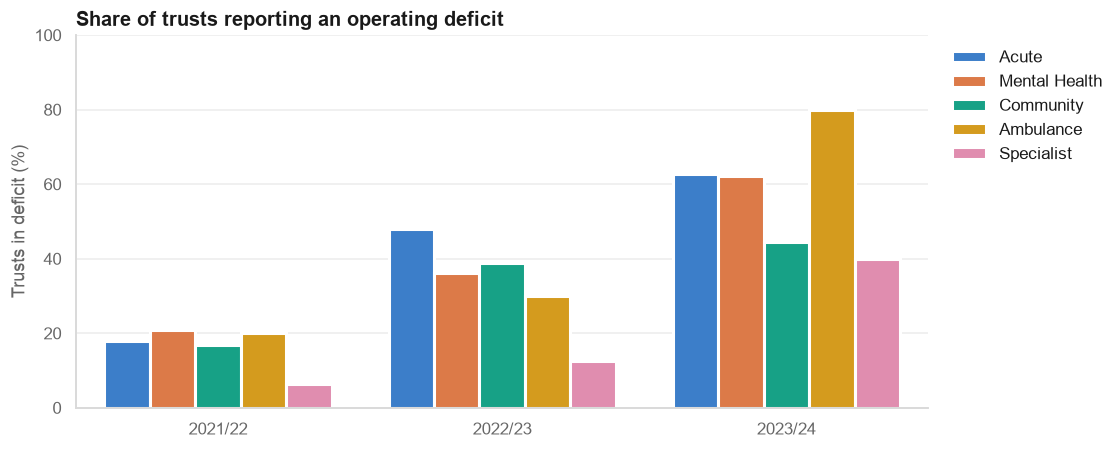

Trusts in deficit nationally: 18% in 2021/22, 60% in 2023/24


In [3]:
# One chart from the query result: the share in deficit, by sector and year
plot = deficit[deficit.sector != "All sectors"]
fig, ax = plt.subplots(figsize=(10, 4.4))
import seaborn as sns
sns.barplot(data=plot, x="financial_year", y="pct_in_deficit", hue="sector",
            hue_order=nhs.SECTOR_ORDER, palette=nhs.SECTOR_COLOURS, edgecolor="white", linewidth=2, ax=ax)
ax.set(title="Share of trusts reporting an operating deficit", xlabel=None, ylabel="Trusts in deficit (%)", ylim=(0, 100))
ax.legend(title=None, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

national = deficit[deficit.sector == "All sectors"].set_index("financial_year").pct_in_deficit
print(f"Trusts in deficit nationally: {national.iloc[0]:.0f}% in {national.index[0]}, "
      f"{national.iloc[-1]:.0f}% in {national.index[-1]}")

## 1.2 Combined result by sector, with the year-on-year movement

The CTE adds trusts up to one row per sector and year; `LAG()` then reads the previous year's result on
the same row, so the change needs no self-join. The window is declared once with `WINDOW w AS (...)`.

In [4]:
nhs.sql("01_financial_pressure", "sector_result_trend")

`sql/analysis/01_financial_pressure.sql` → **sector_result_trend**

```sql
-- The combined operating result of each sector, and how far it moved from the
-- year before.
-- Technique: aggregate in a CTE, then LAG() over the sector's own years.
WITH sector_year AS (
    SELECT
        sector,
        financial_year,
        SUM(operating_surplus_000s) AS operating_surplus_000s,
        SUM(total_income_000s)      AS total_income_000s
    FROM v_kpis
    GROUP BY sector, financial_year
)
SELECT
    sector,
    financial_year,
    ROUND(operating_surplus_000s / 1000, 1)                                AS operating_surplus_m,
    ROUND(100 * operating_surplus_000s / NULLIF(total_income_000s, 0), 2)  AS operating_margin_pct,
    ROUND((operating_surplus_000s
           - LAG(operating_surplus_000s) OVER w) / 1000, 1)                AS change_on_prior_year_m
FROM sector_year
WINDOW w AS (PARTITION BY sector ORDER BY financial_year)
ORDER BY sector, financial_year;
```

,sector,financial_year,operating_surplus_m,operating_margin_pct,change_on_prior_year_m
0,Acute,2021/22,"1,274.3",1.5,NaN
1,Acute,2022/23,9.9,0.0,"-1,264.4"
2,Acute,2023/24,"-1,282.2",-1.3,"-1,292.1"
3,Ambulance,2021/22,8.7,0.2,NaN
4,Ambulance,2022/23,-4.4,-0.1,-13.0
5,Ambulance,2023/24,-45.8,-1.1,-41.4
6,Community,2021/22,31.5,0.8,NaN
7,Community,2022/23,8.9,0.2,-22.6
8,Community,2023/24,-14.9,-0.3,-23.8
9,Mental Health,2021/22,214.1,1.3,NaN


## 1.3 Spread of margins inside each sector

A sector total can hide a few very large deficits, so this looks at the median trust. MySQL has no
`MEDIAN()` function: each trust is numbered within its sector with `ROW_NUMBER()`, the sector size comes
from `COUNT(*) OVER`, and the median is the average of the one or two middle rows. That works for odd and
even counts alike.

In [5]:
nhs.sql("01_financial_pressure", "margin_distribution_latest_year")

`sql/analysis/01_financial_pressure.sql` → **margin_distribution_latest_year**

```sql
-- The spread of operating margins inside each sector in the latest year: the
-- median trust, the worst and best, and how many sit below -5%.
-- Technique: MySQL has no MEDIAN(), so rank each trust with ROW_NUMBER() and
-- COUNT() OVER the sector, then average the one or two middle rows.
WITH latest AS (
    SELECT MAX(financial_year) AS financial_year FROM nhs_silver.fct_tac
),
ranked AS (
    SELECT
        s.sector,
        100 * s.operating_surplus_000s / NULLIF(s.total_income_000s, 0) AS margin_pct,
        ROW_NUMBER() OVER (PARTITION BY s.sector
                           ORDER BY s.operating_surplus_000s / NULLIF(s.total_income_000s, 0)) AS rn,
        COUNT(*)     OVER (PARTITION BY s.sector)                                              AS n
    FROM v_kpis s
    JOIN latest l ON l.financial_year = s.financial_year
)
SELECT
    sector,
    MAX(n)                                                                    AS trusts,
    ROUND(AVG(CASE WHEN rn IN (FLOOR((n + 1) / 2), CEIL((n + 1) / 2))
                   THEN margin_pct END), 2)                                   AS median_margin_pct,
    ROUND(MIN(margin_pct), 2)                                                 AS worst_margin_pct,
    ROUND(MAX(margin_pct), 2)                                                 AS best_margin_pct,
    SUM(margin_pct < -5)                                                      AS trusts_below_minus_5pct
FROM ranked
GROUP BY sector
ORDER BY median_margin_pct;
```

,sector,trusts,median_margin_pct,worst_margin_pct,best_margin_pct,trusts_below_minus_5pct
0,Acute,118,-0.8,-22.9,4.4,21
1,Mental Health,45,-0.4,-14.7,5.1,7
2,Ambulance,10,-0.2,-7.2,0.6,2
3,Community,18,0.1,-5.2,3.5,1
4,Specialist,15,0.3,-13.7,5.5,1


## 1.4 Who fell into deficit, and who recovered

A count in deficit hides movement underneath it. `LAG()` puts each trust's previous status on the same
row as this year's, and conditional `SUM()`s pivot the four possible transitions into columns.

In [6]:
nhs.sql("01_financial_pressure", "surplus_deficit_transitions")

`sql/analysis/01_financial_pressure.sql` → **surplus_deficit_transitions**

```sql
-- How trusts moved between surplus and deficit from one year to the next. A
-- board cares less about the count in deficit than about how many fell into it.
-- Technique: LAG() to put each trust's prior-year status on the same row, then
-- a pivot of the transitions with conditional aggregation.
WITH status AS (
    SELECT
        org_code,
        financial_year,
        IF(operating_surplus_000s < 0, 'Deficit', 'Surplus')  AS status_now,
        LAG(IF(operating_surplus_000s < 0, 'Deficit', 'Surplus'))
            OVER (PARTITION BY org_code ORDER BY financial_year) AS status_before,
        LAG(financial_year)
            OVER (PARTITION BY org_code ORDER BY financial_year) AS prior_year
    FROM v_kpis
)
SELECT
    CONCAT(prior_year, ' → ', financial_year)                                  AS period,
    SUM(status_before = 'Surplus' AND status_now = 'Surplus')                  AS stayed_in_surplus,
    SUM(status_before = 'Surplus' AND status_now = 'Deficit')                  AS fell_into_deficit,
    SUM(status_before = 'Deficit' AND status_now = 'Surplus')                  AS recovered_to_surplus,
    SUM(status_before = 'Deficit' AND status_now = 'Deficit')                  AS stayed_in_deficit
FROM status
WHERE status_before IS NOT NULL
GROUP BY prior_year, financial_year
ORDER BY financial_year;
```

,period,stayed_in_surplus,fell_into_deficit,recovered_to_surplus,stayed_in_deficit
0,2021/22 → 2022/23,115,60,10,27
1,2022/23 → 2023/24,63,58,19,66


## 1.5 The largest deficits, before and after impairments

The fact table is long (one row per trust, year and SubCode), so the impairment charge (`EXP0260`) is
pulled out by SubCode in its own CTE and joined to the KPI view. `ROW_NUMBER()` keeps the three largest
deficits per sector. Where the *underlying* result (before impairments) is close to break-even, the
reported deficit is mostly a non-cash write-down; where it stays deeply negative, the trust has a genuine
operating problem.

In [7]:
nhs.sql("01_financial_pressure", "largest_deficits_with_impairments")

`sql/analysis/01_financial_pressure.sql` → **largest_deficits_with_impairments**

```sql
-- The three largest operating deficits in each sector in the latest year, with
-- the impairment charge pulled straight from the fact table. Impairments are
-- non-cash write-downs; adding them back gives the underlying result, which is
-- closer to how NHS England judges a trust's performance.
-- Technique: pivot one line out of the long (EAV) fact table, join it to the
-- view, and keep the top N per group with ROW_NUMBER().
WITH latest AS (
    SELECT MAX(financial_year) AS financial_year FROM nhs_silver.fct_tac
),
impairments AS (
    SELECT org_code, financial_year, SUM(total_000s) AS impairments_000s
    FROM nhs_silver.fct_tac
    WHERE worksheet_name = 'TAC08 Op Exp'
      AND sub_code = 'EXP0260'               -- Impairments net of reversals
    GROUP BY org_code, financial_year
),
ranked AS (
    SELECT
        s.sector,
        s.organisation_name,
        s.operating_surplus_000s,
        COALESCE(i.impairments_000s, 0)                                 AS impairments_000s,
        s.operating_surplus_000s + COALESCE(i.impairments_000s, 0)      AS underlying_surplus_000s,
        s.total_income_000s,
        ROW_NUMBER() OVER (PARTITION BY s.sector ORDER BY s.operating_surplus_000s) AS deficit_rank
    FROM v_kpis s
    JOIN latest l ON l.financial_year = s.financial_year
    LEFT JOIN impairments i
           ON i.org_code = s.org_code AND i.financial_year = s.financial_year
    WHERE s.operating_surplus_000s < 0
)
SELECT
    sector,
    deficit_rank,
    organisation_name,
    ROUND(operating_surplus_000s / 1000, 1)                                  AS operating_surplus_m,
    ROUND(impairments_000s / 1000, 1)                                        AS impairments_m,
    ROUND(underlying_surplus_000s / 1000, 1)                                 AS underlying_surplus_m,
    ROUND(100 * underlying_surplus_000s / NULLIF(total_income_000s, 0), 2)   AS underlying_margin_pct
FROM ranked
WHERE deficit_rank <= 3
ORDER BY sector, deficit_rank;
```

,sector,deficit_rank,organisation_name,operating_surplus_m,impairments_m,underlying_surplus_m,underlying_margin_pct
0,Acute,1,University Hospitals Sussex NHS Foundation Trust,-153.4,164.0,10.6,0.7
1,Acute,2,East Kent Hospitals University NHS Foundation ...,-145.1,34.4,-110.7,-11.8
2,Acute,3,St George's University Hospitals NHS Foundatio...,-95.8,115.9,20.1,1.6
3,Ambulance,1,South Central Ambulance Service NHS Foundation...,-25.3,5.6,-19.7,-5.6
4,Ambulance,2,South East Coast Ambulance Service NHS Foundat...,-19.2,15.4,-3.7,-1.1
5,Ambulance,3,North East Ambulance Service NHS Foundation Trust,-3.4,1.3,-2.1,-0.9
6,Community,1,Solent NHS Trust,-13.8,16.5,2.8,1.0
7,Community,2,Derbyshire Community Health Services NHS Found...,-11.8,9.9,-1.9,-0.8
8,Community,3,Sussex Community NHS Foundation Trust,-7.7,7.4,-0.3,-0.1
9,Mental Health,1,Mersey Care NHS Foundation Trust,-60.2,73.5,13.3,1.8
